# Amazon reviews: small, diverse dataset (< 13k rows)

Everything lives in this one notebook (preprocessing included, no separate `k.py`).

Goal: a compact dataset that still **generalises** across product types.

Design choices:
1. **Category diversity**: equal share from each of the 29 training categories.
2. **Balanced ratings in train**: raw data is ~66% 5-star, so train is sampled evenly across 1-5 stars within each category.
3. **Realistic eval sets**: valid / test keep the natural rating distribution.
4. **Unseen-category test (OOD)**: 4 whole categories never appear in train.
5. **Total budget: 12,000 rows** (limit 13k).

Run from `/Users/asterchrome/Documents/RCS` (where `data/splits/` lives).

In [1]:
import re
import os
import spacy
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SEED = 42
N_TRAIN, N_VALID, N_TEST, N_OOD = 8000, 1000, 1000, 2000   # total 12,000
MIN_WORDS = 3                                               # drop 1-2 word reviews

Preprocessing functions

In [ ]:
nlp = spacy.load("en_core_web_sm", disable=["tagger", "parser", "ner", "lemmatizer", "attribute_ruler"])

# Pre-compile regex
HEX = re.compile(r'&#x[0-9A-Fa-f]+;')
DEC = re.compile(r'&#\d+;')
ASCII = re.compile(r'[^\x00-\x7F]+')
URL = re.compile(r'http\S+|www\S+')
ESCAPES = re.compile(r'[\n\t\r]+')

def clean_regex_only(text):
    """Only performs the fast regex string replacement."""
    x = str(text).lower()
    x = ESCAPES.sub(" ", x)
    x = x.replace("&amp;", "&").replace("<br />", '')
    x = HEX.sub('', x)
    x = DEC.sub("'", x)
    x = ASCII.sub("'", x)
    x = URL.sub('LINK', x)
    return x.strip()

def preprocess(text, nlp):
    clean_text = clean_regex_only(text)
    sent = nlp.tokenizer(clean_text)
    sent = ' '.join([tok.text for tok in sent])
    return sent

def apply_preprocess(X):
    return [preprocess(sent, nlp) for sent in tqdm(X)]

## 1. Load the existing splits

In [3]:
def load(name):
    d = pd.read_csv(f"data/splits/{name}.csv.gz")
    d["title"] = d["title"].fillna("")
    d["text"] = d["text"].fillna("")
    d = d[d["text"].str.split().str.len() >= MIN_WORDS]
    d = d.drop_duplicates("text")
    d["rating"] = d["rating"].astype(int)
    return d.reset_index(drop=True)

raw = {n: load(n) for n in ["train", "valid", "test", "ood_test"]}
for n, d in raw.items():
    print(f"{n:9s} {len(d):7d} rows, {d['category'].nunique()} categories")

train      499209 rows, 29 categories
valid       63120 rows, 29 categories
test        63109 rows, 29 categories
ood_test    89803 rows, 4 categories


## 2. Sample: balanced for train, natural for evaluation

In [4]:
def balanced_sample(d, n_total):
    """Equal rows per category, and equal rows per star rating inside each category."""
    per_cat = n_total // d["category"].nunique()
    per_rating = max(1, per_cat // 5)
    parts = []
    for cat, g in d.groupby("category"):
        for r in range(1, 6):
            x = g[g["rating"] == r]
            parts.append(x.sample(min(len(x), per_rating), random_state=SEED))
    return pd.concat(parts)

def natural_sample(d, n_total):
    """Equal rows per category, natural rating distribution."""
    per_cat = max(1, n_total // d["category"].nunique())
    parts = [g.sample(min(len(g), per_cat), random_state=SEED) for _, g in d.groupby("category")]
    return pd.concat(parts)

small = {
    "train":    balanced_sample(raw["train"], N_TRAIN),
    "valid":    natural_sample(raw["valid"], N_VALID),
    "test":     natural_sample(raw["test"], N_TEST),
    "ood_test": natural_sample(raw["ood_test"], N_OOD),
}
small = {n: d.sample(frac=1, random_state=SEED).reset_index(drop=True) for n, d in small.items()}

total = sum(len(d) for d in small.values())
for n, d in small.items():
    print(f"{n:9s} {len(d):6d}")
print("TOTAL:", total)
assert total < 13_000, "over budget!"

train       7975
valid        986
test         986
ood_test    2000
TOTAL: 11947


## 3. Preprocess with `k.py` (lowercase, regex clean, spaCy tokenizer)

In [5]:
for name, d in small.items():
    print(f"\n=== {name} ===")
    d["text_clean"] = apply_preprocess(d["text"])
    d["title_clean"] = apply_preprocess(d["title"])
    d["input"] = d["title_clean"] + " . " + d["text_clean"]   # title + body as one string
    d["sentiment"] = d["rating"].map({1: "negative", 2: "negative", 3: "neutral", 4: "positive", 5: "positive"})


=== train ===


  0%|          | 0/7975 [00:00<?, ?it/s]

  0%|          | 0/7975 [00:00<?, ?it/s]


=== valid ===


  0%|          | 0/986 [00:00<?, ?it/s]

  0%|          | 0/986 [00:00<?, ?it/s]

... (2 outputs left out)

  0%|          | 0/986 [00:00<?, ?it/s]


=== ood_test ===


  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

## 4. Sanity checks

In [6]:
tr = small["train"]
print("Train rating distribution:")
print(tr["rating"].value_counts(normalize=True).sort_index().round(3))
print("\nTrain rows per category (min / max):",
      tr["category"].value_counts().min(), "/", tr["category"].value_counts().max())
print("\nOOD categories:", sorted(small["ood_test"]["category"].unique()))
print("Category overlap train vs OOD:",
      set(tr["category"]) & set(small["ood_test"]["category"]) or "none (good)")

for i in range(3):
    print("\nORIGINAL:", tr["text"].iloc[i][:150])
    print("CLEANED: ", tr["text_clean"].iloc[i][:150])

Train rating distribution:
rating
1    0.2
2    0.2
3    0.2
4    0.2
5    0.2
Name: proportion, dtype: float64

Train rows per category (min / max): 275 / 275

OOD categories: ['Automotive', 'Books', 'Pet_Supplies', 'Software']
Category overlap train vs OOD: none (good)

ORIGINAL: Not sure where the issue lies, but I suspect it's the source; streaming these shows via my PS3, the picture is stretched instead of being displayed wi
CLEANED:  not sure where the issue lies , but i suspect it 's the source ; streaming these shows via my ps3 , the picture is stretched instead of being displaye

ORIGINAL: Fun Game. Great Moves !!
CLEANED:  fun game . great moves ! !

ORIGINAL: Thank you love it
CLEANED:  thank you love it


count    7975.000000
mean       62.946834
std        90.345363
min         4.000000
25%        21.000000
50%        39.000000
75%        70.000000
max      1810.000000
Name: input, dtype: float64


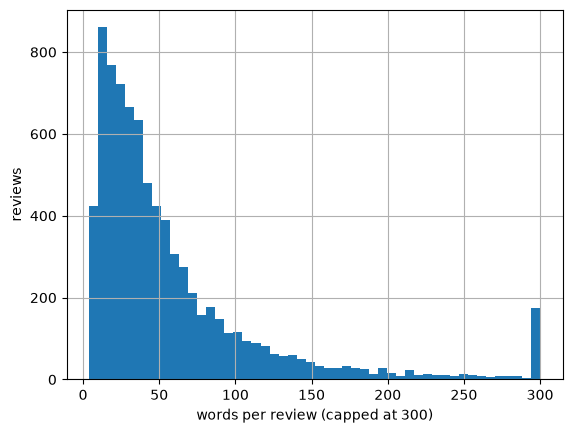

In [ ]:
wc = tr["input"].str.split().str.len()
print(wc.describe())
wc.clip(upper=300).hist(bins=50)
plt.xlabel("words per review ") #cap 300
plt.ylabel("reviews")
plt.show()

## 5. Save

In [8]:
import os
os.makedirs("data/small", exist_ok=True)
cols = ["rating", "sentiment", "category", "title", "text", "title_clean", "text_clean", "input"]
for name, d in small.items():
    d[cols].to_csv(f"data/small/{name}.csv", index=False)
    print("saved", name, d.shape, "-> data/small/%s.csv" % name)

saved train (7975, 13) -> data/small/train.csv
saved valid (986, 13) -> data/small/valid.csv
saved test (986, 13) -> data/small/test.csv
saved ood_test (2000, 13) -> data/small/ood_test.csv
